# Geographic Variation in Medicare Cardiac Rhythm Monitoring Services and Payments

**An Exploratory Analysis of 2024 CMS Medicare Data**

## Project overview
This project explores geographic patterns in Medicare-billed services for **three selected HCPCS codes** related to cardiac rhythm monitoring: **93285, 93291, and 93298**. Payment analysis focuses specifically on **93298** (remote evaluation of a cardiac rhythm monitor system, up to 30 days).

**Research questions**
1. How do service volumes vary across geographic areas?
2. What is the mix of the three selected HCPCS codes?
3. How do reported Medicare payments for HCPCS 93298 vary geographically?
4. How are payment levels associated with service volume and office-based service share?
5. How do office (`O`) and facility (`F`) payment amounts differ?

**Data source:** CMS, *Medicare Physician & Other Practitioners – by Geography and Service*, 2024.  
**Tools:** Python, pandas, NumPy, Matplotlib.  
**Interpretation:** Geographic units are CMS state-level reporting categories, which include the District of Columbia; they are not all U.S. states.

> **Reproducibility:** Place the downloaded CMS CSV in the same directory as this notebook (or edit `csv_path` below). Run all cells from top to bottom. Figures are written to `figures/`.


## 1. Data loading and quality checks
Load the CMS dataset and inspect its shape, fields, and geographic reporting categories.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Set this explicitly if your folder contains more than one CSV.
csv_path = None  # e.g. Path("data/medicare_geography_2024.csv")
if csv_path is None:
    csv_files = sorted(Path(".").glob("*.csv"))
    if len(csv_files) != 1:
        raise FileNotFoundError(
            f"Expected exactly one CSV beside the notebook, found {len(csv_files)}: {csv_files}. "
            "Set csv_path to the CMS data file explicitly."
        )
    csv_path = csv_files[0]

df = pd.read_csv(csv_path, low_memory=False, dtype={"HCPCS_Cd": "string"})
print("Loaded:", csv_path)
print("Shape:", df.shape)


Loaded: MUP_PHY_R26_P05_V10_D24_Geo.csv
Shape: (268350, 15)


In [2]:
df.head()

,Rndrng_Prvdr_Geo_Lvl,Rndrng_Prvdr_Geo_Cd,Rndrng_Prvdr_Geo_Desc,HCPCS_Cd,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Rndrng_Prvdrs,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
0,National,NaN,National,0001U,Red blood cell typing,N,O,7,100,100.0,100,881.466600,525.950400,525.950400,705.600000
1,National,NaN,National,0002M,"Molecular pathology test for liver disease, in...",N,O,6,416,426.0,426,508.519624,491.465023,484.618333,486.614953
2,National,NaN,National,0003M,"Molecular pathology test for liver disease, in...",N,O,24,8635,8998.0,8998,515.495073,490.235042,484.595947,487.695770
3,National,NaN,National,0005U,Test for detecting genes associated with prost...,N,O,3,15557,15705.0,15705,995.007202,744.017408,744.017408,744.800000
4,National,NaN,National,00100,Anesthesia for procedure on saliva gland,N,F,7658,6284,9341.0,9340,2198.127103,210.499720,165.519569,164.328563


In [3]:
df.shape

(268350, 15)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 268350 entries, 0 to 268349
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Rndrng_Prvdr_Geo_Lvl   268350 non-null  str    
 1   Rndrng_Prvdr_Geo_Cd    254882 non-null  str    
 2   Rndrng_Prvdr_Geo_Desc  268345 non-null  str    
 3   HCPCS_Cd               268350 non-null  string 
 4   HCPCS_Desc             268350 non-null  str    
 5   HCPCS_Drug_Ind         268350 non-null  str    
 6   Place_Of_Srvc          268350 non-null  str    
 7   Tot_Rndrng_Prvdrs      268350 non-null  int64  
 8   Tot_Benes              268350 non-null  int64  
 9   Tot_Srvcs              268350 non-null  float64
 10  Tot_Bene_Day_Srvcs     268350 non-null  int64  
 11  Avg_Sbmtd_Chrg         268350 non-null  float64
 12  Avg_Mdcr_Alowd_Amt     268350 non-null  float64
 13  Avg_Mdcr_Pymt_Amt      268350 non-null  float64
 14  Avg_Mdcr_Stdzd_Amt     268350 non-null  float64

In [5]:
missing_geo = df[df["Rndrng_Prvdr_Geo_Cd"].isna()]

missing_geo["Rndrng_Prvdr_Geo_Lvl"].value_counts()

Rndrng_Prvdr_Geo_Lvl
National    13463
State           5
Name: count, dtype: int64

In [6]:
state_missing = df[
    (df["Rndrng_Prvdr_Geo_Lvl"] == "State") &
    (df["Rndrng_Prvdr_Geo_Cd"].isna())
]

state_missing[
    ["Rndrng_Prvdr_Geo_Lvl",
     "Rndrng_Prvdr_Geo_Cd",
     "Rndrng_Prvdr_Geo_Desc",
     "HCPCS_Cd",
     "Tot_Srvcs"]
]

,Rndrng_Prvdr_Geo_Lvl,Rndrng_Prvdr_Geo_Cd,Rndrng_Prvdr_Geo_Desc,HCPCS_Cd,Tot_Srvcs
13463,State,NaN,NaN,90833,70.0
13464,State,NaN,NaN,99223,29.0
13465,State,NaN,NaN,99232,77.0
13466,State,NaN,NaN,99233,238.0
13467,State,NaN,NaN,99239,32.0


In [7]:
df_state = df[
    (df["Rndrng_Prvdr_Geo_Lvl"] == "State") &
    (df["Rndrng_Prvdr_Geo_Desc"].notna())
].copy()

print(df_state.shape)

(254882, 15)


In [8]:
print("Original dataset:", df.shape)

print("State-level dataset:", df_state.shape)

print(
    "Missing geographic descriptions:",
    df_state["Rndrng_Prvdr_Geo_Desc"].isna().sum()
)

Original dataset: (268350, 15)
State-level dataset: (254882, 15)
Missing geographic descriptions: 0


### Geographic scope
Keep rows reported at the CMS `State` geographic level with a nonmissing geographic description. This category includes DC. Some records can have missing geographic codes; the filtering criterion here is the **description**, not the geographic code.

## 2. Broad geographic context
These totals span **all HCPCS services in the filtered CMS data**, not only cardiac monitoring. They provide context and should not be interpreted as cardiac monitoring volumes.

In [9]:
state_services = (
    df_state.groupby("Rndrng_Prvdr_Geo_Desc")["Tot_Srvcs"]
    .sum()
)

state_services.head()

Rndrng_Prvdr_Geo_Desc
Alabama           59022290.8
Alaska             6866283.3
American Samoa          36.0
Arizona           96614299.0
Arkansas          39077623.4
Name: Tot_Srvcs, dtype: float64

In [10]:
state_services_sorted = state_services.sort_values(
    ascending=False
)

state_services_sorted.head(10)

Rndrng_Prvdr_Geo_Desc
California        369730316.3
Florida           369172263.8
Texas             276994280.6
New York          196337754.6
New Jersey        152202079.5
Pennsylvania      151234485.4
Illinois          143369175.6
North Carolina    109488068.4
Maryland          105956987.1
Virginia           97099761.3
Name: Tot_Srvcs, dtype: float64

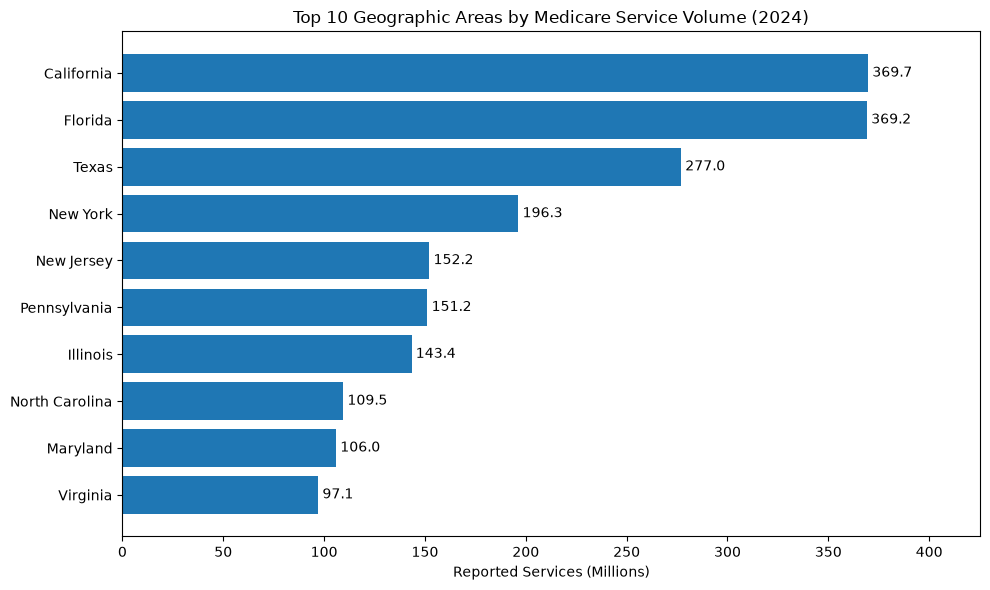

In [11]:
import matplotlib.pyplot as plt
top10 = state_services_sorted.head(10)

top10_millions = top10 / 1_000_000

top10_millions


fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    top10_millions.index,
    top10_millions.values
)

ax.invert_yaxis()

ax.set_xlabel("Reported Services (Millions)")
ax.set_title(
    "Top 10 Geographic Areas by Medicare Service Volume (2024)"
)

ax.bar_label(
    bars,
    fmt="%.1f",
    padding=3
)

ax.set_xlim(0, top10_millions.max() * 1.15)

plt.tight_layout()

from pathlib import Path

Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/top10_medicare_services_2024.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 3. Select cardiac rhythm monitoring HCPCS codes
The initial keyword scan is exploratory; the final scope is the explicitly selected codes. Other codes containing “cardiac” may refer to unrelated procedures.

In [12]:
cardiac_services = df_state[
    df_state["HCPCS_Desc"].str.contains(
        "cardiac",
        case=False,
        na=False
    )
]

print("Number of records:", cardiac_services.shape[0])

print("Unique HCPCS codes:", cardiac_services["HCPCS_Cd"].nunique())

Number of records: 527
Unique HCPCS codes: 16


In [13]:
unique_cardiac_codes = (
    cardiac_services[["HCPCS_Cd", "HCPCS_Desc"]]
    .drop_duplicates()
    .sort_values("HCPCS_Cd")
)

print(unique_cardiac_codes.to_string(index=False))

HCPCS_Cd                                                                                                                                                                                                                                                       HCPCS_Desc
   0696T                                                                                                                     Body surface-activation mapping of cardiac resynchronization therapy device, with review, and report, at time of follow-up device evaluation
   78445                                                                                                                                                                                                                 Nuclear medicine study of non-cardiac blood flow
   82550                                                                                                                                                                                                  

In [14]:
selected_codes = ["93285", "93291", "93298"]

rhythm_data = df_state[
    df_state["HCPCS_Cd"].astype(str).isin(selected_codes)
].copy()

print("Shape:", rhythm_data.shape)
print("Codes:", rhythm_data["HCPCS_Cd"].unique())

Shape: (281, 15)
Codes: <StringArray>
['93285', '93291', '93298']
Length: 3, dtype: string


In [15]:
code_descriptions = (
    rhythm_data[
        ["HCPCS_Cd", "HCPCS_Desc"]
    ]
    .drop_duplicates()
    .sort_values("HCPCS_Cd")
)

print(code_descriptions.to_string(index=False))

HCPCS_Cd                                                        HCPCS_Desc
   93285                      Programming of cardiac rhythm monitor system
   93291                       Evaluation of cardiac rhythm monitor system
   93298 Evaluation of cardiac rhythm monitor system, remote up to 30 days


In [16]:
# Select cardiac rhythm monitoring services
selected_codes = ["93285", "93291", "93298"]

rhythm_data = df_state[
    df_state["HCPCS_Cd"].isin(selected_codes)
].copy()

print("Number of records:", len(rhythm_data))
print("Unique HCPCS codes:", rhythm_data["HCPCS_Cd"].nunique())

rhythm_data.head()

Number of records: 281
Unique HCPCS codes: 3


,Rndrng_Prvdr_Geo_Lvl,Rndrng_Prvdr_Geo_Cd,Rndrng_Prvdr_Geo_Desc,HCPCS_Cd,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Rndrng_Prvdrs,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
17511,State,01,Alabama,93285,Programming of cardiac rhythm monitor system,N,F,9,47,49.0,49,113.183673,23.641429,17.093673,17.033061
17512,State,01,Alabama,93285,Programming of cardiac rhythm monitor system,N,O,24,69,75.0,75,136.208000,51.570533,35.210267,38.471200
17520,State,01,Alabama,93291,Evaluation of cardiac rhythm monitor system,N,F,15,36,37.0,37,69.945946,17.144595,13.693784,13.520270
17521,State,01,Alabama,93291,Evaluation of cardiac rhythm monitor system,N,O,52,189,285.0,285,113.049474,38.076035,27.963789,32.024772
17530,State,01,Alabama,93298,"Evaluation of cardiac rhythm monitor system, r...",N,F,19,197,897.0,897,45.270903,23.003389,17.250089,17.908707


In [17]:
state_rhythm_services = (
    rhythm_data
    .groupby("Rndrng_Prvdr_Geo_Desc")["Tot_Srvcs"]
    .sum()
    .sort_values(ascending=False)
)

print(state_rhythm_services.head(10))

Rndrng_Prvdr_Geo_Desc
New York          311477.0
Florida           191389.0
California        154045.0
Texas             115304.0
New Jersey         73902.0
Pennsylvania       67160.0
Arizona            52420.0
Illinois           46296.0
South Carolina     42973.0
Ohio               41019.0
Name: Tot_Srvcs, dtype: float64


In [18]:
state_code_table = rhythm_data.pivot_table(
    index="Rndrng_Prvdr_Geo_Desc",
    columns="HCPCS_Cd",
    values="Tot_Srvcs",
    aggfunc="sum",
    fill_value=0
)

state_code_table.head()

HCPCS_Cd,93285,93291,93298
Rndrng_Prvdr_Geo_Desc,,,
Alabama,124.0,322.0,11245.0
Alaska,143.0,30.0,1922.0
Arizona,3404.0,1715.0,47301.0
Arkansas,325.0,794.0,6682.0
California,5379.0,5217.0,143449.0


In [19]:
top10_states = state_rhythm_services.head(10).index

top10_code_table = state_code_table.loc[top10_states]

print(top10_code_table)

HCPCS_Cd                93285   93291     93298
Rndrng_Prvdr_Geo_Desc                          
New York               4623.0  9350.0  297504.0
Florida                4265.0  9359.0  177765.0
California             5379.0  5217.0  143449.0
Texas                  4469.0  4796.0  106039.0
New Jersey             3305.0  4170.0   66427.0
Pennsylvania           2713.0  1393.0   63054.0
Arizona                3404.0  1715.0   47301.0
Illinois               1564.0  1519.0   43213.0
South Carolina          940.0  1586.0   40447.0
Ohio                    596.0  1070.0   39353.0


In [20]:
# Calculate the total selected services for each state
state_totals = state_code_table.sum(axis=1)

# Calculate the percentage of each HCPCS code
service_mix = state_code_table.div(state_totals, axis=0) * 100

# Display the top 10 states
top10_service_mix = service_mix.loc[top10_states]

print(top10_service_mix.round(2))

HCPCS_Cd               93285  93291  93298
Rndrng_Prvdr_Geo_Desc                     
New York                1.48   3.00  95.51
Florida                 2.23   4.89  92.88
California              3.49   3.39  93.12
Texas                   3.88   4.16  91.96
New Jersey              4.47   5.64  89.89
Pennsylvania            4.04   2.07  93.89
Arizona                 6.49   3.27  90.23
Illinois                3.38   3.28  93.34
South Carolina          2.19   3.69  94.12
Ohio                    1.45   2.61  95.94


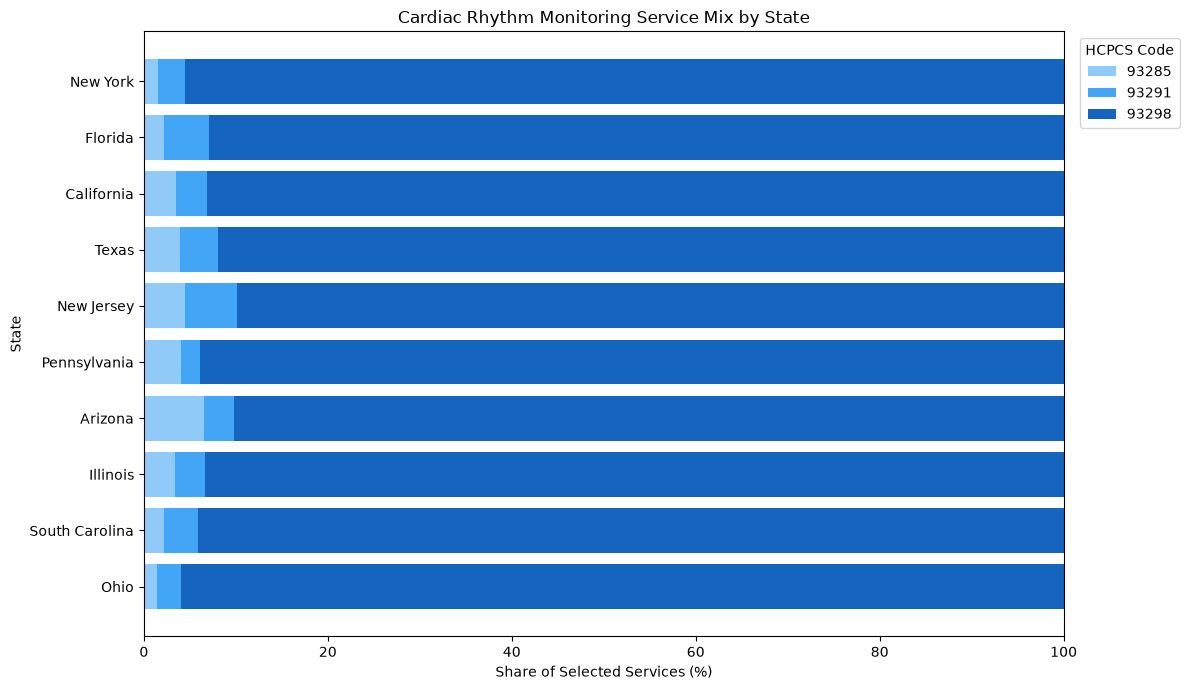

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare the data
states = top10_service_mix.index
codes = ["93285", "93291", "93298"]

colors = ["#90CAF9", "#42A5F5", "#1565C0"]

fig, ax = plt.subplots(figsize=(12, 7))

# Track where the next segment should begin
left = np.zeros(len(states))

for code, color in zip(codes, colors):
    values = top10_service_mix[code]

    ax.barh(
        states,
        values,
        left=left,
        label=code,
        color=color
    )

    left += values.to_numpy()

ax.set_xlabel("Share of Selected Services (%)")
ax.set_ylabel("State")
ax.set_title(
    "Cardiac Rhythm Monitoring Service Mix by State"
)

ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.legend(
    title="HCPCS Code",
    loc="upper left",
    bbox_to_anchor=(1.01, 1)
)

plt.tight_layout()
Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/service_mix_top10.png", dpi=300, bbox_inches="tight")
plt.show()

**Service-mix interpretation:** Percentages are calculated **only among 93285, 93291, and 93298**, not among all cardiac procedures, patients, or devices. Billing frequency and unit definitions may differ by code.

## 4. HCPCS 93298: service-weighted Medicare payment
Estimate the payment total as reported service count × reported average Medicare payment, then divide the sum of these estimates by the total reported services for each geographic area. This is an **estimate based on aggregated CMS values**, not a claim about actual provider revenue or profit.

In [22]:
remote_payment = rhythm_data[
    rhythm_data["HCPCS_Cd"] == "93298"
][
    [
        "Rndrng_Prvdr_Geo_Desc",
        "Place_Of_Srvc",
        "Tot_Srvcs",
        "Avg_Mdcr_Pymt_Amt"
    ]
].copy()

print(remote_payment.head(10))
print("Number of records:", len(remote_payment))

      Rndrng_Prvdr_Geo_Desc Place_Of_Srvc  Tot_Srvcs  Avg_Mdcr_Pymt_Amt
17530               Alabama             F      897.0          17.250089
17531               Alabama             O    10348.0          52.527519
20448                Alaska             F       79.0          17.920506
20449                Alaska             O     1843.0          71.905317
26024               Arizona             F      876.0          17.971096
26025               Arizona             O    46425.0          48.799660
30734              Arkansas             F     1400.0          16.629600
30735              Arkansas             O     5282.0          36.092874
39148            California             F     6283.0          19.431238
39149            California             O   137166.0          64.789358
Number of records: 101


In [23]:
# Count records by place of service
print(remote_payment["Place_Of_Srvc"].value_counts())

# Check missing values
print(
    remote_payment[
        ["Tot_Srvcs", "Avg_Mdcr_Pymt_Amt"]
    ].isna().sum()
)

# Check number of geographic areas
print(
    "Unique geographic areas:",
    remote_payment["Rndrng_Prvdr_Geo_Desc"].nunique()
)

Place_Of_Srvc
O    51
F    50
Name: count, dtype: int64
Tot_Srvcs            0
Avg_Mdcr_Pymt_Amt    0
dtype: int64
Unique geographic areas: 51


In [24]:
remote_payment["Estimated_Total_Payment"] = (
    remote_payment["Tot_Srvcs"]
    * remote_payment["Avg_Mdcr_Pymt_Amt"]
)

remote_payment.head()

,Rndrng_Prvdr_Geo_Desc,Place_Of_Srvc,Tot_Srvcs,Avg_Mdcr_Pymt_Amt,Estimated_Total_Payment
17530,Alabama,F,897.0,17.250089,15473.330000
17531,Alabama,O,10348.0,52.527519,543554.769996
20448,Alaska,F,79.0,17.920506,1415.720000
20449,Alaska,O,1843.0,71.905317,132521.500000
26024,Arizona,F,876.0,17.971096,15742.680000


In [25]:
state_payment = remote_payment.groupby(
    "Rndrng_Prvdr_Geo_Desc"
)[
    ["Tot_Srvcs", "Estimated_Total_Payment"]
].sum()

state_payment.head()

,Tot_Srvcs,Estimated_Total_Payment
Rndrng_Prvdr_Geo_Desc,,
Alabama,11245.0,5.590281e+05
Alaska,1922.0,1.339372e+05
Arizona,47301.0,2.281267e+06
Arkansas,6682.0,2.139240e+05
California,143449.0,9.008984e+06


In [26]:
# Calculate weighted average Medicare payment
state_payment["Weighted_Avg_Payment"] = (
    state_payment["Estimated_Total_Payment"]
    / state_payment["Tot_Srvcs"]
)

# Display results rounded to 2 decimal places
print(state_payment.head(10).round(2))

                       Tot_Srvcs  Estimated_Total_Payment  \
Rndrng_Prvdr_Geo_Desc                                       
Alabama                  11245.0                559028.10   
Alaska                    1922.0                133937.22   
Arizona                  47301.0               2281266.89   
Arkansas                  6682.0                213924.00   
California              143449.0               9008983.52   
Colorado                 30133.0               1573056.31   
Connecticut              16023.0               1076526.24   
Delaware                  7804.0                459139.13   
District of Columbia      1590.0                103857.60   
Florida                 177765.0              10994491.11   

                       Weighted_Avg_Payment  
Rndrng_Prvdr_Geo_Desc                        
Alabama                               49.71  
Alaska                                69.69  
Arizona                               48.23  
Arkansas                             

In [27]:
payment_ranking = state_payment.sort_values(
    by="Weighted_Avg_Payment",
    ascending=False
)

print(
    payment_ranking[
        ["Tot_Srvcs", "Weighted_Avg_Payment"]
    ].head(10).round(2)
)

                       Tot_Srvcs  Weighted_Avg_Payment
Rndrng_Prvdr_Geo_Desc                                 
New York                297504.0                 72.39
New Jersey               66427.0                 71.60
Alaska                    1922.0                 69.69
Connecticut              16023.0                 67.19
District of Columbia      1590.0                 65.32
Maryland                 24747.0                 64.59
California              143449.0                 62.80
Florida                 177765.0                 61.85
Delaware                  7804.0                 58.83
Illinois                 43213.0                 57.46


## 5. Service volume and payment correlations
Use Pearson and Spearman correlations, plus a sensitivity check excluding New York. These are **descriptive associations**, not causal effects.

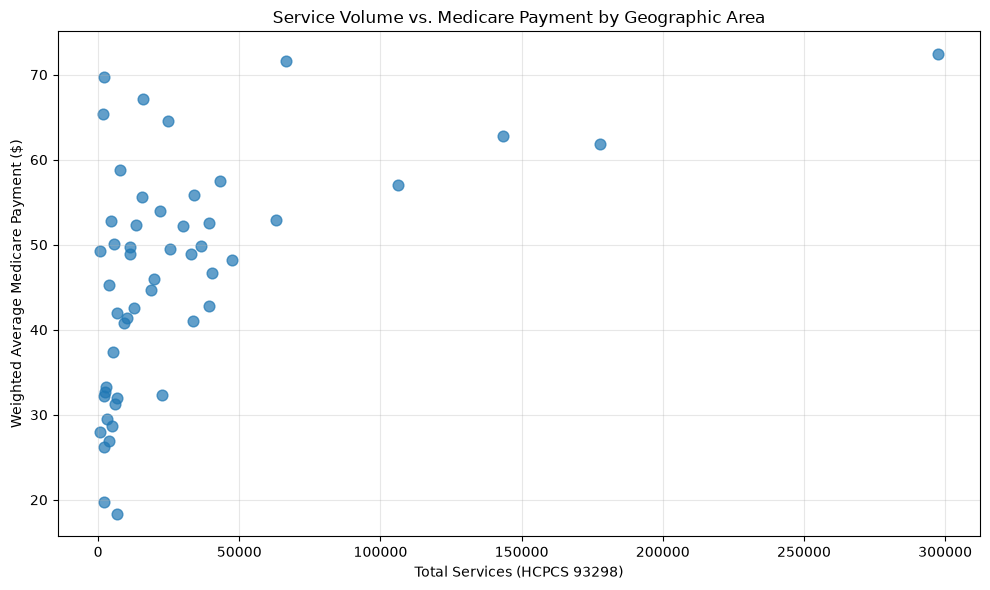

In [28]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    state_payment["Tot_Srvcs"],
    state_payment["Weighted_Avg_Payment"],
    alpha=0.7,
    s=60
)

ax.set_xlabel("Total Services (HCPCS 93298)")
ax.set_ylabel("Weighted Average Medicare Payment ($)")
ax.set_title(
    "Service Volume vs. Medicare Payment by Geographic Area"
)

ax.grid(alpha=0.3)

plt.tight_layout()
Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/volume_vs_payment_93298.png", dpi=300, bbox_inches="tight")
plt.show()

In [29]:
correlation = state_payment[
    "Tot_Srvcs"
].corr(
    state_payment["Weighted_Avg_Payment"]
)

print("Pearson correlation:", round(correlation, 3))

Pearson correlation: 0.497


In [30]:
# Exclude New York for sensitivity analysis
payment_without_ny = state_payment.drop(
    index="New York"
)

# Calculate Pearson correlation again
correlation_without_ny = payment_without_ny[
    "Tot_Srvcs"
].corr(
    payment_without_ny["Weighted_Avg_Payment"]
)

print("Pearson with NY:", round(correlation, 3))
print("Pearson without NY:", round(correlation_without_ny, 3))

Pearson with NY: 0.497
Pearson without NY: 0.454


In [31]:
spearman_corr = state_payment[
    "Tot_Srvcs"
].corr(
    state_payment["Weighted_Avg_Payment"],
    method="spearman"
)

print("Pearson correlation:", round(correlation, 3))
print("Spearman correlation:", round(spearman_corr, 3))

Pearson correlation: 0.497
Spearman correlation: 0.527


## 6. Office share and payment composition
`O` denotes office/nonfacility and `F` denotes facility. Overall payment is a weighted combination of setting-specific payments, so correlations with office share are partly mechanical.

In [32]:
# Create a table of service volumes by setting
setting_table = remote_payment.pivot_table(
    index="Rndrng_Prvdr_Geo_Desc",
    columns="Place_Of_Srvc",
    values="Tot_Srvcs",
    aggfunc="sum",
    fill_value=0
)

print(setting_table.head())

Place_Of_Srvc               F         O
Rndrng_Prvdr_Geo_Desc                  
Alabama                 897.0   10348.0
Alaska                   79.0    1843.0
Arizona                 876.0   46425.0
Arkansas               1400.0    5282.0
California             6283.0  137166.0


In [33]:
setting_table["Office_Share"] = (
    setting_table["O"]
    / setting_table[["F", "O"]].sum(axis=1)
    * 100
)

print(setting_table.head().round(2))

Place_Of_Srvc               F         O  Office_Share
Rndrng_Prvdr_Geo_Desc                                
Alabama                 897.0   10348.0         92.02
Alaska                   79.0    1843.0         95.89
Arizona                 876.0   46425.0         98.15
Arkansas               1400.0    5282.0         79.05
California             6283.0  137166.0         95.62


In [34]:
analysis_df = state_payment.join(
    setting_table[["Office_Share"]]
)

print(analysis_df.head().round(2))

                       Tot_Srvcs  Estimated_Total_Payment  \
Rndrng_Prvdr_Geo_Desc                                       
Alabama                  11245.0                559028.10   
Alaska                    1922.0                133937.22   
Arizona                  47301.0               2281266.89   
Arkansas                  6682.0                213924.00   
California              143449.0               9008983.52   

                       Weighted_Avg_Payment  Office_Share  
Rndrng_Prvdr_Geo_Desc                                      
Alabama                               49.71         92.02  
Alaska                                69.69         95.89  
Arizona                               48.23         98.15  
Arkansas                              32.01         79.05  
California                            62.80         95.62  


In [35]:
office_payment_corr = analysis_df[
    "Office_Share"
].corr(
    analysis_df["Weighted_Avg_Payment"]
)

print(
    "Office Share vs. Payment:",
    round(office_payment_corr, 3)
)

Office Share vs. Payment: 0.774


## 7. Facility vs. office payment comparisons
Compare settings only where both reported payment values exist. Do **not** interpret missing records as zero payment.

In [36]:
setting_payment = remote_payment.pivot_table(
    index="Rndrng_Prvdr_Geo_Desc",
    columns="Place_Of_Srvc",
    values="Avg_Mdcr_Pymt_Amt",
    aggfunc="mean"
)

print(setting_payment.head().round(2))

Place_Of_Srvc              F      O
Rndrng_Prvdr_Geo_Desc              
Alabama                17.25  52.53
Alaska                 17.92  71.91
Arizona                17.97  48.80
Arkansas               16.63  36.09
California             19.43  64.79


In [37]:
setting_payment["Payment_Difference"] = (
    setting_payment["O"]
    - setting_payment["F"]
)

print(setting_payment.head().round(2))

Place_Of_Srvc              F      O  Payment_Difference
Rndrng_Prvdr_Geo_Desc                                  
Alabama                17.25  52.53               35.28
Alaska                 17.92  71.91               53.98
Arizona                17.97  48.80               30.83
Arkansas               16.63  36.09               19.46
California             19.43  64.79               45.36


In [38]:
print(setting_payment[["F", "O"]].isna().sum())

print(
    setting_payment[
        setting_payment[["F", "O"]].isna().any(axis=1)
    ]
)

Place_Of_Srvc
F    1
O    0
dtype: int64
Place_Of_Srvc           F          O  Payment_Difference
Rndrng_Prvdr_Geo_Desc                                   
Wyoming               NaN  49.289345                 NaN


In [39]:
# Keep geographic areas with both payment values
paired_payment = setting_payment.dropna(
    subset=["F", "O"]
).copy()

# Count areas where Office payment is higher
higher_office_count = (
    paired_payment["Payment_Difference"] > 0
).sum()

total_paired_areas = len(paired_payment)

percentage_higher = (
    higher_office_count / total_paired_areas * 100
)

print("Areas with both settings:", total_paired_areas)
print("Areas with higher Office payment:", higher_office_count)
print("Percentage:", round(percentage_higher, 2), "%")

Areas with both settings: 50
Areas with higher Office payment: 50
Percentage: 100.0 %


In [40]:
payment_gap_ranking = paired_payment.sort_values(
    by="Payment_Difference",
    ascending=False
)

print(
    payment_gap_ranking[
        ["F", "O", "Payment_Difference"]
    ].head(10).round(2)
)

Place_Of_Srvc              F      O  Payment_Difference
Rndrng_Prvdr_Geo_Desc                                  
Massachusetts          18.31  74.35               56.04
New York               18.76  74.65               55.89
New Jersey             19.54  75.00               55.46
Alaska                 17.92  71.91               53.98
Connecticut            18.10  71.70               53.60
Wisconsin              17.15  68.22               51.08
District of Columbia   19.22  68.05               48.83
Illinois               18.37  66.86               48.49
Delaware               14.73  62.48               47.75
Minnesota              16.75  64.12               47.36


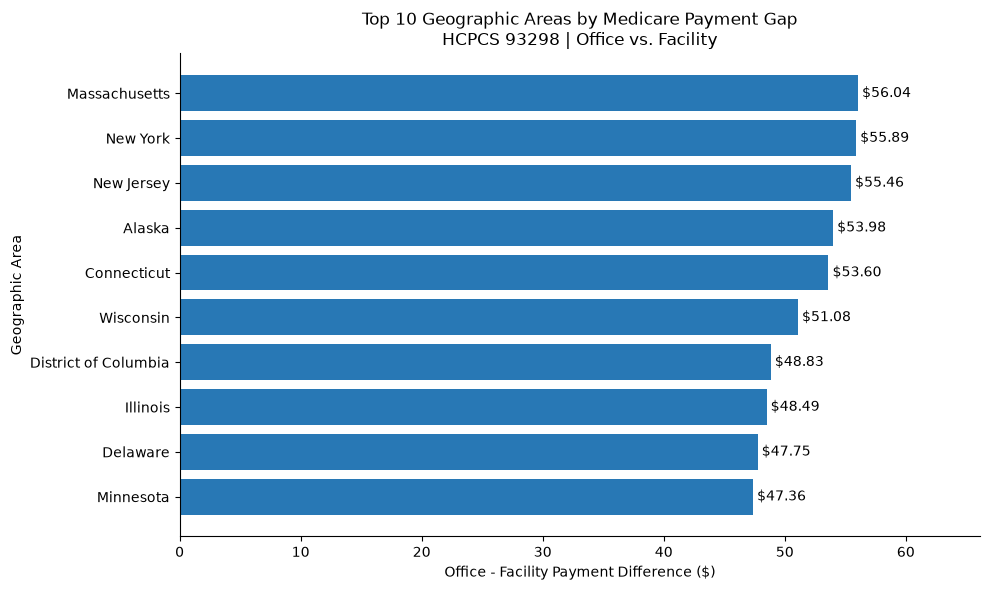

In [41]:
import matplotlib.pyplot as plt

# Select the 10 largest payment gaps
top10_gaps = payment_gap_ranking.head(10)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    top10_gaps.index,
    top10_gaps["Payment_Difference"],
    color="#2878B5"
)

ax.invert_yaxis()

ax.set_xlabel("Office - Facility Payment Difference ($)")
ax.set_ylabel("Geographic Area")
ax.set_title(
    "Top 10 Geographic Areas by Medicare Payment Gap\n"
    "HCPCS 93298 | Office vs. Facility"
)

ax.bar_label(
    bars,
    fmt="$%.2f",
    padding=3
)

ax.set_xlim(
    0,
    top10_gaps["Payment_Difference"].max() * 1.18
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/payment_gap_top10_93298.png", dpi=300, bbox_inches="tight")
plt.show()

In [42]:
# Compare geographic payment variability
payment_variability = paired_payment[
    ["F", "O"]
].agg(["mean", "std", "min", "max"])

print(payment_variability.round(2))

Place_Of_Srvc      F      O
mean           17.84  56.66
std             1.06  11.05
min            14.73  20.56
max            21.28  75.00


## 8. Validation and correlation matrix
Verify the geographic area × setting combinations are unique, then compare office share, office payment, and weighted average payment.

In [43]:
duplicate_check = remote_payment.duplicated(
    subset=["Rndrng_Prvdr_Geo_Desc", "Place_Of_Srvc"]
)

print("Duplicate combinations:", duplicate_check.sum())
print("Total records:", len(remote_payment))

Duplicate combinations: 0
Total records: 101


In [44]:
analysis_df["Office_Payment"] = setting_payment["O"]

print(
    analysis_df[
        ["Weighted_Avg_Payment", "Office_Share", "Office_Payment"]
    ].head().round(2)
)

                       Weighted_Avg_Payment  Office_Share  Office_Payment
Rndrng_Prvdr_Geo_Desc                                                    
Alabama                               49.71         92.02           52.53
Alaska                                69.69         95.89           71.91
Arizona                               48.23         98.15           48.80
Arkansas                              32.01         79.05           36.09
California                            62.80         95.62           64.79


In [45]:
correlations = analysis_df[
    ["Weighted_Avg_Payment", "Office_Share", "Office_Payment"]
].corr()

print(correlations.round(3))

                      Weighted_Avg_Payment  Office_Share  Office_Payment
Weighted_Avg_Payment                 1.000         0.774           0.735
Office_Share                         0.774         1.000           0.184
Office_Payment                       0.735         0.184           1.000


## 9. Key findings

Results observed during the exploratory analysis (recalculate by running the notebook with the same source file):

- **Service volume:** New York had the largest combined reported service volume among the three selected codes, followed by Florida and California.
- **Code mix:** HCPCS 93298 dominated the volume **within the three selected codes**.
- **Geographic payments:** New York had the highest service-weighted average Medicare payment for 93298, approximately **$72.39** per reported service.
- **Volume–payment association:** Pearson **r = 0.497**; excluding New York **r = 0.454**; Spearman **r = 0.527**.
- **Setting differences:** Among **50 geographic areas with both setting records**, the office average exceeded the facility average in **50/50**. Wyoming lacked a facility record in this extract.
- **Largest office–facility gaps:** Massachusetts **$56.04**, New York **$55.89**, New Jersey **$55.46**.
- **Setting-specific geographic variation:** Across the 50 paired areas, the unweighted geographic mean (SD) was **$56.66 ($11.05)** for office and **$17.84 ($1.06)** for facility.
- **Correlations:** Weighted average payment vs. office share **r = 0.774**; vs. office payment **r = 0.735**; office share vs. office payment **r = 0.184**.

## 10. Limitations and interpretation

1. **Selected billing codes:** The three HCPCS codes do not represent the entire cardiac monitoring market or all remote monitoring services.
2. **Aggregated geographic data:** Service counts are not unique patients or devices; no patient-level outcomes or clinical effectiveness can be inferred.
3. **Payment measure:** Estimated total payment is derived from rounded/aggregated service counts and averages. It is not net revenue, margin, or profitability.
4. **Data coverage:** CMS reporting and suppression may lead to absent records. A missing facility row (e.g., Wyoming) is not equivalent to zero services.
5. **Mechanical relationships:** Weighted payment is computed from office share and setting-specific payment amounts. Correlations involving these components are not independent evidence of causal effects.
6. **Cross-sectional scope:** One data year cannot establish time trends or causal mechanisms. Geographic payment differences can also reflect Medicare payment rules and other unmeasured factors.
7. **Geographic weighting:** Means and standard deviations of setting-specific payments across areas give each area equal weight; they are not national service-weighted averages.

## 11. Conclusion

Reported Medicare payment levels for HCPCS 93298 varied across geographic areas and service settings. Office-based reported average payments were higher than facility-based amounts in every area with both records, and office payments varied more across areas. The results motivate further study of service-setting mix and payment rules, while remaining descriptive rather than causal.
